In [2]:
import pandas as pd
import numpy as np

import scipy.stats as stats

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.model_selection import cross_val_score

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeClassifier

from sklearn.preprocessing import FunctionTransformer
from sklearn.compose import ColumnTransformer


In [3]:
df = pd.read_csv("train.csv",usecols=["Age","Fare","Survived"])

In [4]:
df

,Survived,Age,Fare
0,0,22.0,7.2500
1,1,38.0,71.2833
2,1,26.0,7.9250
3,1,35.0,53.1000
4,0,35.0,8.0500
...,...,...,...
886,0,27.0,13.0000
887,1,19.0,30.0000
888,0,NaN,23.4500
889,1,26.0,30.0000


In [5]:
df.isnull().sum()

Survived      0
Age         177
Fare          0
dtype: int64

In [6]:
df["Age"].fillna(df["Age"].mean(),inplace=True)

In [7]:
df.isnull().sum()

Survived    0
Age         0
Fare        0
dtype: int64

In [8]:
df.head()

,Survived,Age,Fare
0,0,22.0,7.2500
1,1,38.0,71.2833
2,1,26.0,7.9250
3,1,35.0,53.1000
4,0,35.0,8.0500


In [9]:
X_train,X_test,y_train,y_test = train_test_split(
    df.iloc[:,1:3],
    df.iloc[:,0],
    test_size=0.2,
    random_state=42
)

Now Checking wheather Age and Fare are Normally Distributred or not

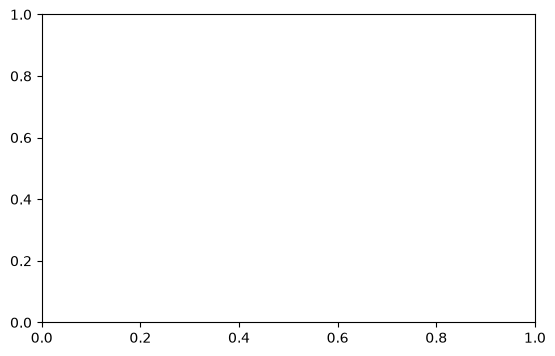

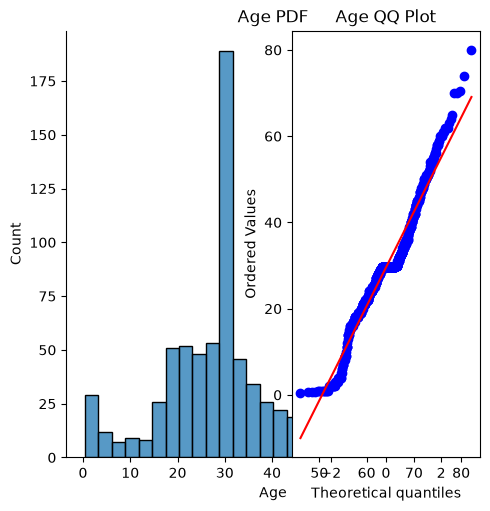

In [10]:
plt.figure(figsize=(14,4))
plt.subplot(121)

sns.displot(X_train["Age"])
plt.title("Age PDF")

plt.subplot(122)
stats.probplot(X_train["Age"],dist='norm',plot=plt)
plt.title('Age QQ Plot')

plt.show()

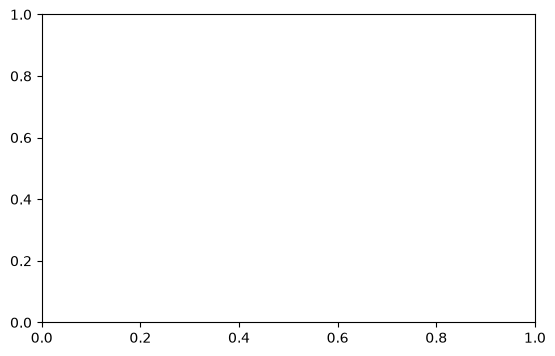

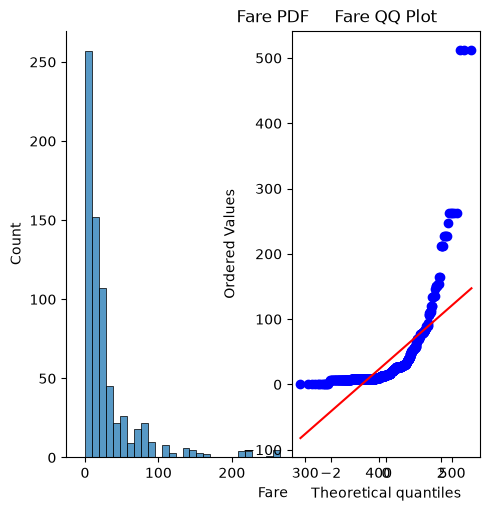

In [11]:
plt.figure(figsize=(14,4))
plt.subplot(121)

sns.displot(X_train["Fare"])
plt.title("Fare PDF")

plt.subplot(122)
stats.probplot(X_train["Fare"],dist='norm',plot=plt)
plt.title('Fare QQ Plot')

plt.show()

In [12]:
from sklearn.linear_model import LogisticRegression

clf = LogisticRegression()
clf2 = DecisionTreeClassifier()

In [13]:
clf.fit(X_train,y_train)
clf2.fit(X_train,y_train)

y_pred = clf.predict(X_test)
y_pred2 = clf2.predict(X_test)

print('Accuracy LR',accuracy_score(y_test,y_pred))
print('Accuracy DT',accuracy_score(y_test,y_pred2))

Accuracy LR 0.6480446927374302
Accuracy DT 0.6536312849162011


In [14]:
trf = FunctionTransformer(func=np.log1p)

In [15]:
X_train_transformed = trf.fit_transform(X_train)
X_test_transformed = trf.fit_transform(X_test)

In [16]:
clf = LogisticRegression()
clf2 = DecisionTreeClassifier()

clf.fit(X_train_transformed,y_train)
clf2.fit(X_train_transformed,y_train)

y_pred = clf.predict(X_test_transformed)
y_pred2 = clf2.predict(X_test_transformed)

print('Accuracy LR',accuracy_score(y_test,y_pred))
print('Accuracy DT',accuracy_score(y_test,y_pred2))


Accuracy LR 0.6815642458100558
Accuracy DT 0.6815642458100558


Fare before and after transformation

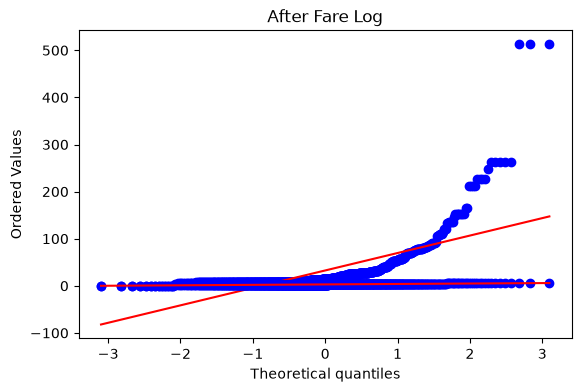

In [17]:
plt.figure(figsize=(14,4))

plt.subplot(121)
stats.probplot(X_train["Fare"],dist='norm',plot=plt)
plt.title('Before Fare Log')


plt.subplot(121)
stats.probplot(X_train_transformed["Fare"],dist='norm',plot=plt)
plt.title('After Fare Log')

plt.show()

For Age column the log tranformation made it worse so we are going to apply log tranformation only to the Fare column only

In [19]:
trf2 = ColumnTransformer([('log',FunctionTransformer(np.log1p),["Fare"])],remainder='passthrough')

X_train_transformed2 = trf2.fit_transform(X_train)
X_test_transformed2 = trf2.transform(X_test)

In [20]:
clf = LogisticRegression()
clf2 = DecisionTreeClassifier()

clf.fit(X_train_transformed2,y_train)
clf2.fit(X_train_transformed2,y_train)

y_pred = clf.predict(X_test_transformed2)
y_pred2 = clf2.predict(X_test_transformed2)

print('Accuracy LR',accuracy_score(y_test,y_pred))
print('Accuracy DT',accuracy_score(y_test,y_pred2))


Accuracy LR 0.6703910614525139
Accuracy DT 0.6536312849162011
